# ViCrop on real data: LLaVA-1.5 + TextVQA

**Paper:** *MLLMs Know Where to Look: Training-free Perception of Small Visual Details with Multimodal LLMs* (ICLR 2025, arXiv:2502.17422)
**Official repo:** https://github.com/saccharomycetes/mllms_know

**What this notebook does**

1. Loads a few real **TextVQA** validation samples (one of the benchmarks the official repo evaluates on).
2. Loads the real **LLaVA-1.5-7B** model (the model used for the paper's main numbers).
3. Runs **ViCrop with relative attention (rel-att)**: answer-to-image attention at LLM layer 14, divided by the attention for the generic prompt, then a sliding-window box and a crop.
4. Compares the answer **without** and **with** the crop, and shows the attention map, box and crop for each sample.

**Setup:** Colab with a GPU (T4 is enough). Runtime > Change runtime type > T4 GPU, then Run all. About 5 min for 30 samples.

The sample is small, so the accuracy gap is noisy. The paper's full TextVQA numbers (LLaVA-1.5: 47.80 to 55.17 with rel-att) come from the whole validation set.

In [1]:
# [setup]
%pip install -q -U transformers accelerate datasets bitsandbytes pillow matplotlib pandas

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.0 which is incompatible.


In [2]:
# [setup]
import re, numpy as np, pandas as pd, torch
from PIL import Image
import matplotlib.pyplot as plt

N = 30            # number of TextVQA samples to run
SEED = 0
LAYER = 14        # LLM layer used for LLaVA-1.5 in the paper
FOUR_BIT = False  # set True if the GPU has less than ~15 GB
DT = torch.float16
MID = "llava-hf/llava-1.5-7b-hf"

GEN = "Write a general description of the image."   # generic prompt q'
SUF = "\nAnswer the question using a single word or phrase."
MEAN = (122, 116, 104)                               # LLaVA pad colour

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 1. Data: TextVQA validation samples

The official repo downloads TextVQA from the Facebook AI release (see its README). Here the same validation set is streamed from the Hugging Face mirror `lmms-lab/textvqa`, so only the samples we need are downloaded.

README.md:   0%|          | 0.00/2.00k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/20 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/20 [00:00<?, ?it/s]

30 samples; columns: ['image_id', 'question_id', 'question', 'question_tokens', 'image', 'image_width', 'image_height', 'flickr_original_url', 'flickr_300k_url', 'answers', 'image_classes', 'set_name', 'ocr_tokens']


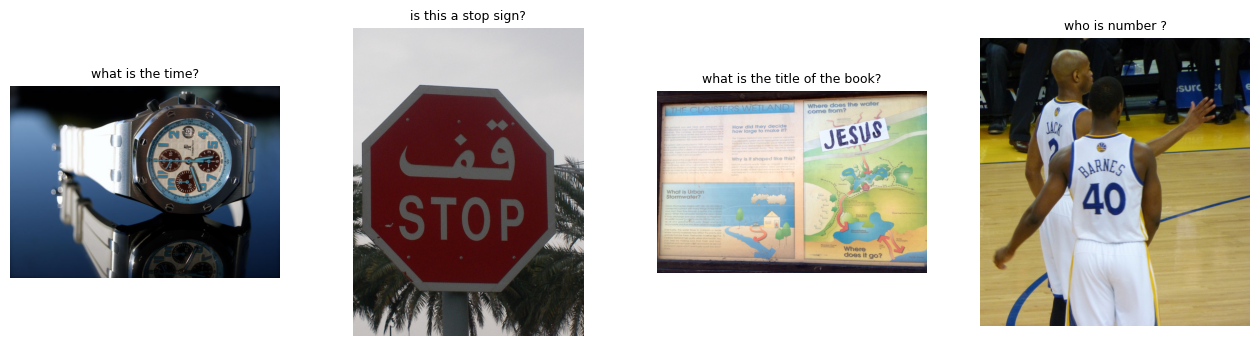

In [3]:
# [data]
from datasets import load_dataset

ds = load_dataset("lmms-lab/textvqa", split="validation", streaming=True)
rows = list(ds.shuffle(seed=SEED, buffer_size=300).take(N))
print(len(rows), "samples; columns:", list(rows[0].keys()))

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, r in zip(ax, rows[:4]):
    a.imshow(r["image"]); a.axis("off")
    a.set_title(r["question"][:45], fontsize=9)
plt.show()

## 2. Model: LLaVA-1.5-7B

`attn_implementation="eager"` is needed so the attention weights can be returned.

In [4]:
# [model]
from transformers import AutoProcessor, LlavaForConditionalGeneration, BitsAndBytesConfig

kw = dict(dtype=DT, attn_implementation="eager", device_map="auto")
if FOUR_BIT:
    kw["quantization_config"] = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=DT)
model = LlavaForConditionalGeneration.from_pretrained(MID, **kw).eval()
proc = AutoProcessor.from_pretrained(MID)
print("loaded on", model.device)

config.json:   0%|          | 0.00/950 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/70.1k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/686 [00:00<?, ?it/s]

...

tokenizer.model: reconstructing file:   0%|          |  0.00B /  500kB            

tokenizer.model: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/41.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

loaded on cuda:0


## 3. ViCrop helpers

LLaVA-1.5 sees a 336x336 image as 24x24 = 576 tokens. Images are padded to a square first (as LLaVA does), so the 24x24 attention grid maps straight onto the padded image.

In [5]:
def sq(im):
    """Pad to a square with LLaVA's mean colour (keeps the 24x24 grid aligned with the image)."""
    w, h = im.size
    s = max(w, h)
    out = Image.new("RGB", (s, s), MEAN)
    out.paste(im, ((s - w) // 2, (s - h) // 2))
    return out


def prompt(q, n=1, suf=SUF):
    return "USER: " + "<image>\n" * n + q + suf + " ASSISTANT:"


def enc(ims, text):
    return proc(images=ims, text=text, return_tensors="pt").to(model.device, DT)


@torch.no_grad()
def ask(ims, q):
    """Answer q given one image (baseline) or [original, crop] (ViCrop)."""
    x = enc(ims, prompt(q, len(ims)))
    out = model.generate(**x, max_new_tokens=16, do_sample=False)
    return proc.decode(out[0, x.input_ids.shape[1]:], skip_special_tokens=True).strip()

In [6]:
@torch.no_grad()
def att(im, text):
    """Attention from the last prompt token (the one that predicts the first answer token)
    to the 576 image tokens, at layer LAYER, averaged over heads -> 24x24."""
    x = enc([im], text)
    o = model(**x, output_attentions=True)
    a = o.attentions[LAYER][0].float().mean(0)[-1]
    m = x.input_ids[0] == proc.tokenizer.convert_tokens_to_ids("<image>")
    assert m.sum() == 576, f"expected 576 image tokens, got {int(m.sum())}"
    return a[m].reshape(24, 24).cpu().numpy()


def rel(im, q):
    """Relative attention: A(q) / A(q'), which cancels the question-independent 'register' tokens."""
    return att(im, prompt(q)) / (att(im, prompt(GEN, suf="")) + 1e-8)


def up(m, s):
    """Nearest-neighbour upsample an NxN map to s x s."""
    i = (np.arange(s) * m.shape[0] // s).clip(0, m.shape[0] - 1)
    return m[np.ix_(i, i)]


def wsum(ii, w, k):
    """Sum inside every w x w window (stride k) from an integral image."""
    a = ii[w:, w:] - ii[:-w, w:] - ii[w:, :-w] + ii[:-w, :-w]
    return a[::k, ::k]


def pick(m, s, base=336, k=8):
    """Paper's box selection: slide windows of 1.0x..2.0x the model resolution over the map,
    keep the best position per size, then take the size whose inside-sum differs most from
    its neighbouring positions. Returns (x0, y0, x1, y1) on the padded image."""
    ii = np.pad(up(m, s), ((1, 0), (1, 0))).cumsum(0).cumsum(1)
    best, top = (0, 0, s, s), -np.inf
    for f in np.arange(1.0, 2.01, 0.2):
        w = int(min(round(f * base), s))
        v = wsum(ii, w, k)
        y, x = np.unravel_index(v.argmax(), v.shape)
        nb = [v[y + dy, x + dx] for dy, dx in ((-1, 0), (1, 0), (0, -1), (0, 1))
              if 0 <= y + dy < v.shape[0] and 0 <= x + dx < v.shape[1]]
        sc = v[y, x] - np.mean(nb) if nb else -np.inf
        if sc > top:
            top, best = sc, (x * k, y * k, x * k + w, y * k + w)
    return best


def vicrop(s, q):
    """Full ViCrop (rel-att): attention map -> box -> crop -> answer from original + crop."""
    m = rel(s, q)
    b = pick(m, s.size[0])
    c = s.crop(b)
    return ask([s, c], q), m, b, c

## 4. Scoring

Standard TextVQA/VQA soft accuracy: `min(#annotators who gave the answer / 3, 1)` after lower-casing and removing punctuation and articles.

In [7]:
def norm(t):
    t = re.sub(r"[^\w\s]", "", t.lower().strip())
    t = re.sub(r"\b(a|an|the)\b", " ", t)
    return " ".join(t.split())


def acc(p, gts):
    p = norm(p)
    return min(sum(norm(g) == p for g in gts) / 3, 1)

## 5. Run on the samples

In [8]:
res = []
for i, r in enumerate(rows):
    s = sq(r["image"].convert("RGB"))
    q, gts = r["question"], r["answers"]
    a0 = ask([s], q)
    a1, m, b, c = vicrop(s, q)
    res.append(dict(i=i, q=q, gts=gts, s=s, m=m, b=b, c=c, a0=a0, a1=a1,
                    s0=acc(a0, gts), s1=acc(a1, gts)))
    print(f"{i:2d} | {q[:42]:42s} | no-crop: {a0[:16]:16s} | ViCrop: {a1[:16]:16s} | gt: {max(set(gts), key=gts.count)}")

 0 | what is the time?                          | no-crop: 12:00            | ViCrop: 1:55             | gt: 5:41
 1 | is this a stop sign?                       | no-crop: Yes              | ViCrop: Yes              | gt: yes
 2 | what is the title of the book?             | no-crop: The closers wetl | ViCrop: Closetters wetla | gt: unanswerable
 3 | who is number ?                            | no-crop: 40               | ViCrop: Barnes           | gt: 40
 4 | what does the big blue bar at the bottom s | no-crop: Simplicity       | ViCrop: Sleeping         | gt: sleeping
 5 | what is the shipping depot?                | no-crop: New york         | ViCrop: John carle & son | gt: john carle & sons
 6 | what kind of paternity test?               | no-crop: Dna              | ViCrop: Dna              | gt: dna
 7 | what is the title of this software functio | no-crop: Textorizer       | ViCrop: Textorizer       | gt: textorizer
 8 | what is in the bottles?                    | no-crop: Be

## 6. Results

samples: 30
no crop :  54.4%
ViCrop  :  64.4%   (fixed 4, broke 2, unchanged 24)


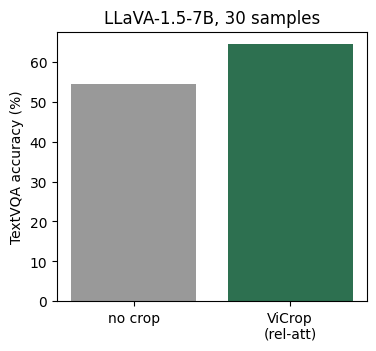

,q,gt,a0,a1,s0,s1
0,what is the time?,5:41,12:00,1:55,0.000000,0.000000
1,is this a stop sign?,yes,Yes,Yes,1.000000,1.000000
2,what is the title of the book?,unanswerable,The closers wetland,Closetters wetland,0.000000,0.000000
3,who is number ?,40,40,Barnes,1.000000,0.333333
4,what does the big blue bar at the bottom say?,sleeping,Simplicity,Sleeping,0.000000,1.000000
5,what is the shipping depot?,john carle & sons,New york,John carle & sons,0.000000,1.000000
6,what kind of paternity test?,dna,Dna,Dna,1.000000,1.000000
7,what is the title of this software function?,textorizer,Textorizer,Textorizer,1.000000,1.000000
8,what is in the bottles?,corona,Beer,Beer,0.333333,0.333333
9,where does the boardwalk look north from?,auditorium,Theater,Auditorium,0.000000,1.000000


In [9]:
df = pd.DataFrame([{k: r[k] for k in ("i", "q", "a0", "a1", "s0", "s1")} for r in res])
df["gt"] = [max(set(r["gts"]), key=r["gts"].count) for r in res]

b0, b1 = df.s0.mean() * 100, df.s1.mean() * 100
fixed, broke = int((df.s1 > df.s0).sum()), int((df.s1 < df.s0).sum())
print(f"samples: {len(df)}")
print(f"no crop : {b0:5.1f}%")
print(f"ViCrop  : {b1:5.1f}%   (fixed {fixed}, broke {broke}, unchanged {len(df) - fixed - broke})")

plt.figure(figsize=(4, 3.5))
plt.bar(["no crop", "ViCrop\n(rel-att)"], [b0, b1], color=["#999999", "#2d7050"])
plt.ylabel("TextVQA accuracy (%)"); plt.title(f"LLaVA-1.5-7B, {len(df)} samples")
plt.show()
df[["q", "gt", "a0", "a1", "s0", "s1"]].head(15)

## 7. What ViCrop sees

Per row: the padded input, the relative-attention heatmap (does the model look at the right place?), the selected window, and the crop that is fed in as extra image tokens.

ViCrop fixed the answer: 4 samples


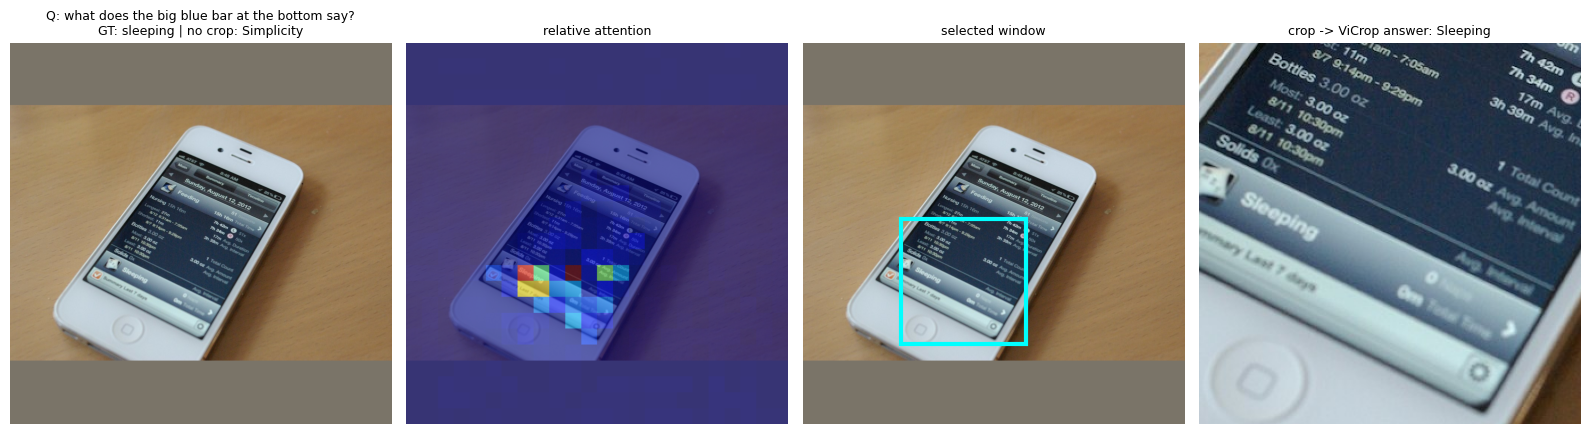

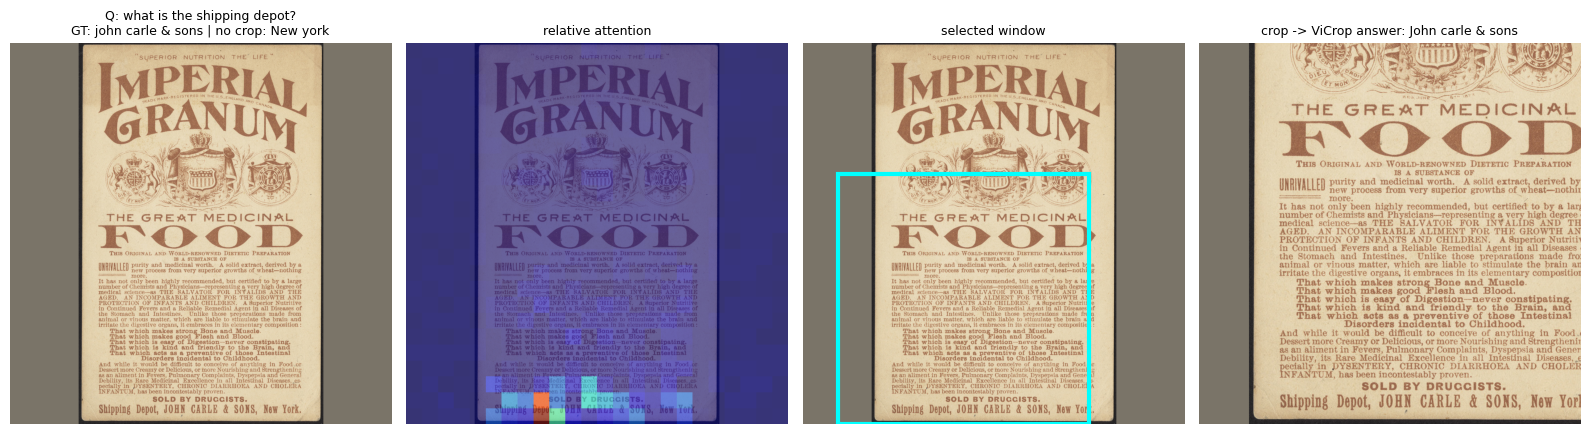

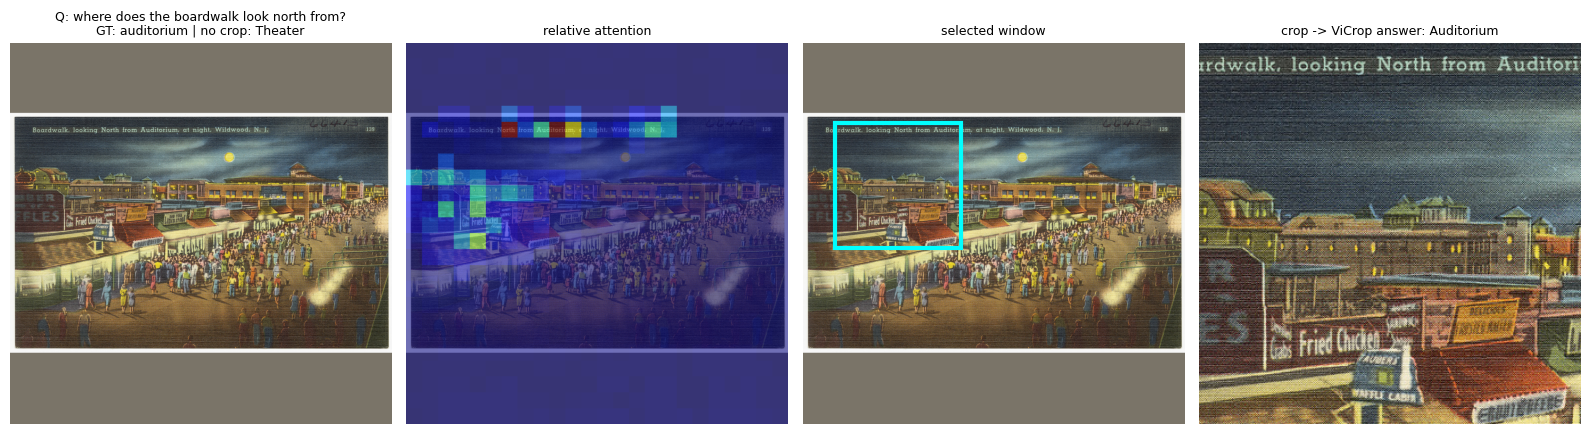

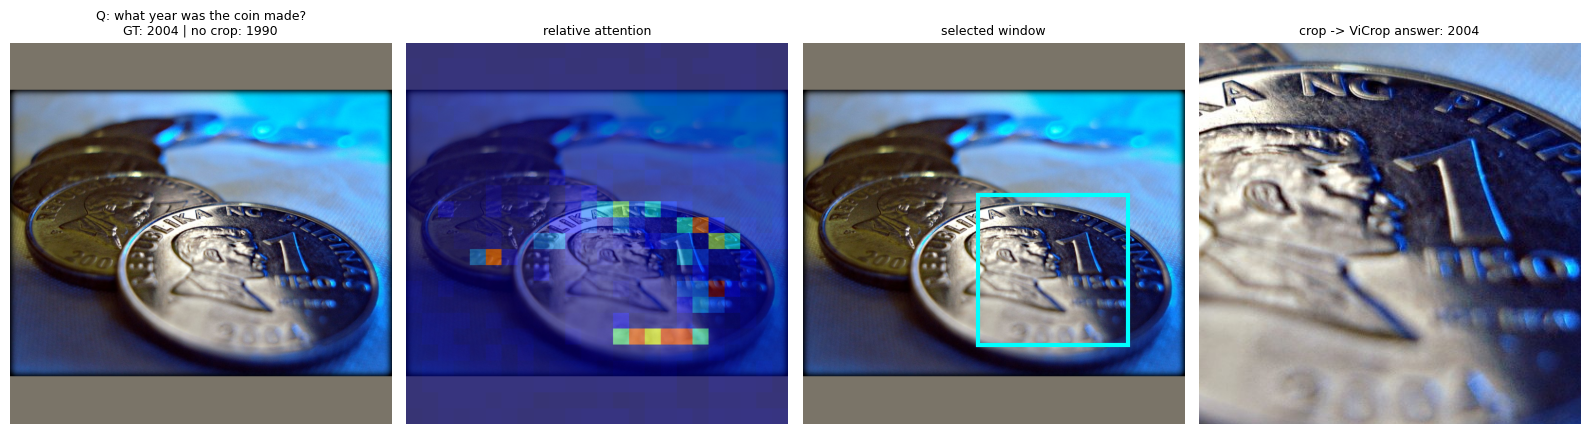

In [10]:
def show(r):
    s = r["s"].size[0]
    gt = max(set(r["gts"]), key=r["gts"].count)
    f, ax = plt.subplots(1, 4, figsize=(16, 4.2))
    ax[0].imshow(r["s"]); ax[0].set_title(f"Q: {r['q'][:50]}\nGT: {gt} | no crop: {r['a0']}", fontsize=9)
    ax[1].imshow(r["s"]); ax[1].imshow(up(r["m"], s), alpha=0.55, cmap="jet"); ax[1].set_title("relative attention", fontsize=9)
    x0, y0, x1, y1 = r["b"]
    ax[2].imshow(r["s"]); ax[2].add_patch(plt.Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec="cyan", lw=3))
    ax[2].set_title("selected window", fontsize=9)
    ax[3].imshow(r["c"]); ax[3].set_title(f"crop -> ViCrop answer: {r['a1']}", fontsize=9)
    for a in ax: a.axis("off")
    plt.tight_layout(); plt.show()


fixed_r = [r for r in res if r["s1"] > r["s0"]]
same_r = [r for r in res if r["s1"] == r["s0"]]
broke_r = [r for r in res if r["s1"] < r["s0"]]
print(f"ViCrop fixed the answer: {len(fixed_r)} samples")
for r in fixed_r[:4]: show(r)

ViCrop broke the answer: 2 samples (failure cases)


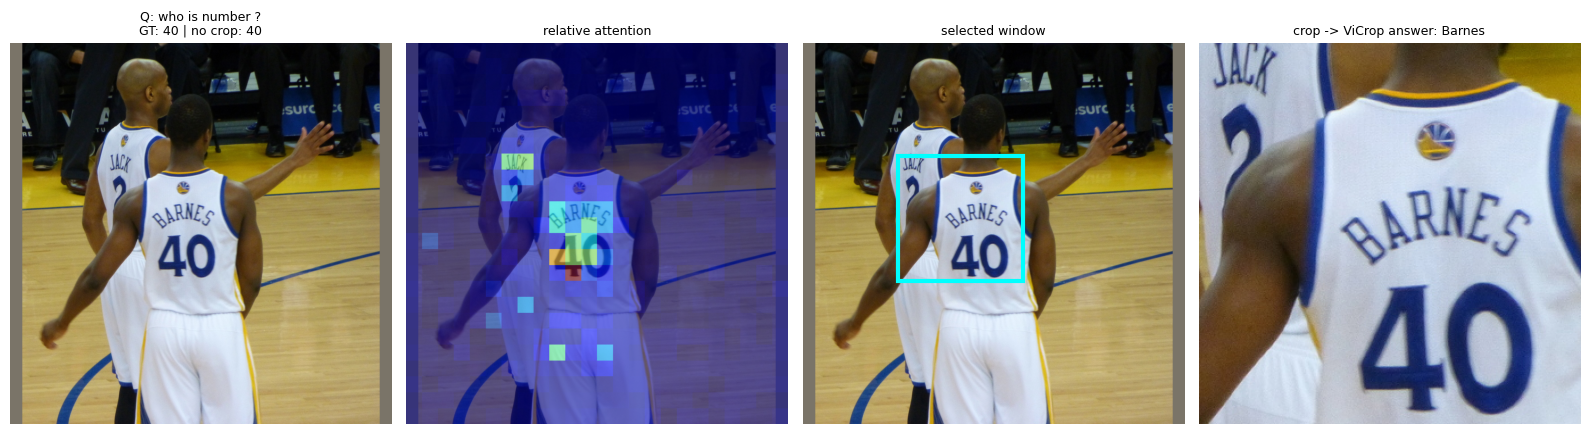

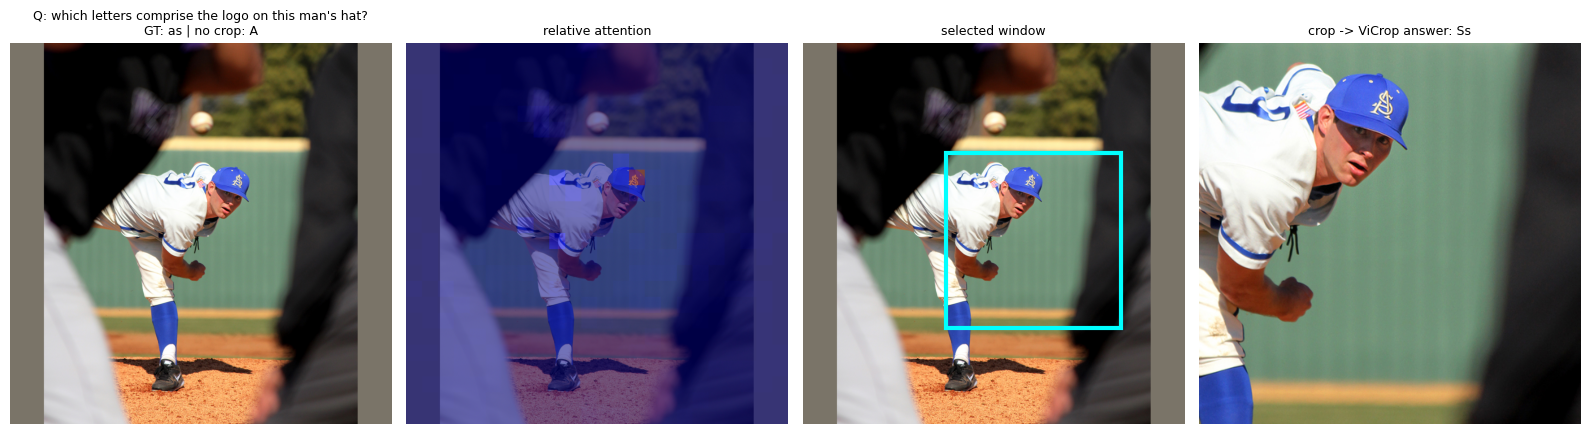

Unchanged examples


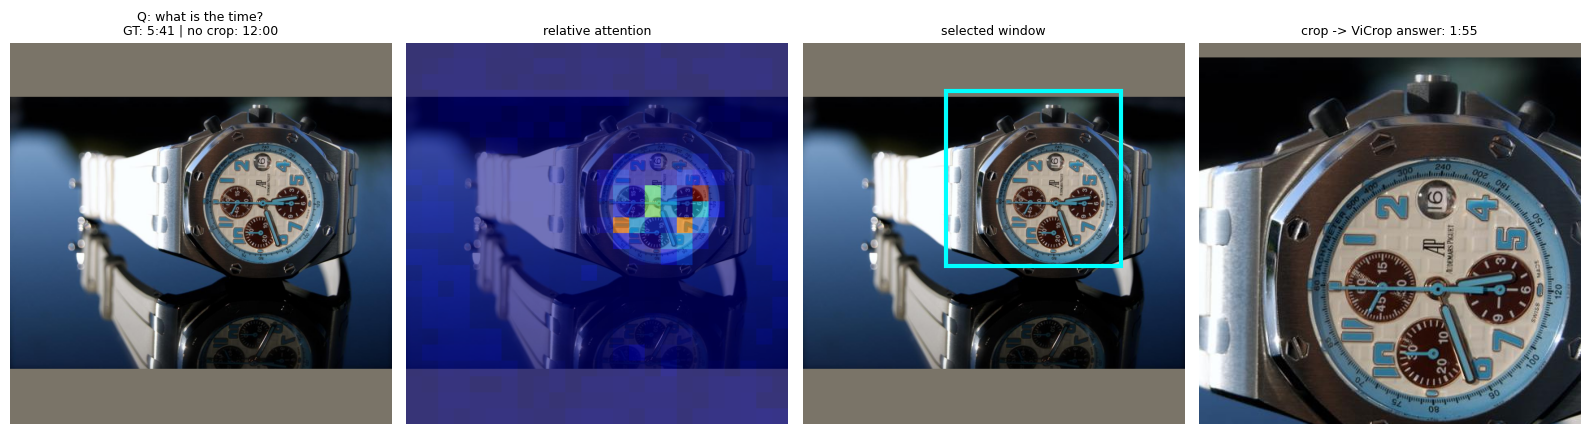

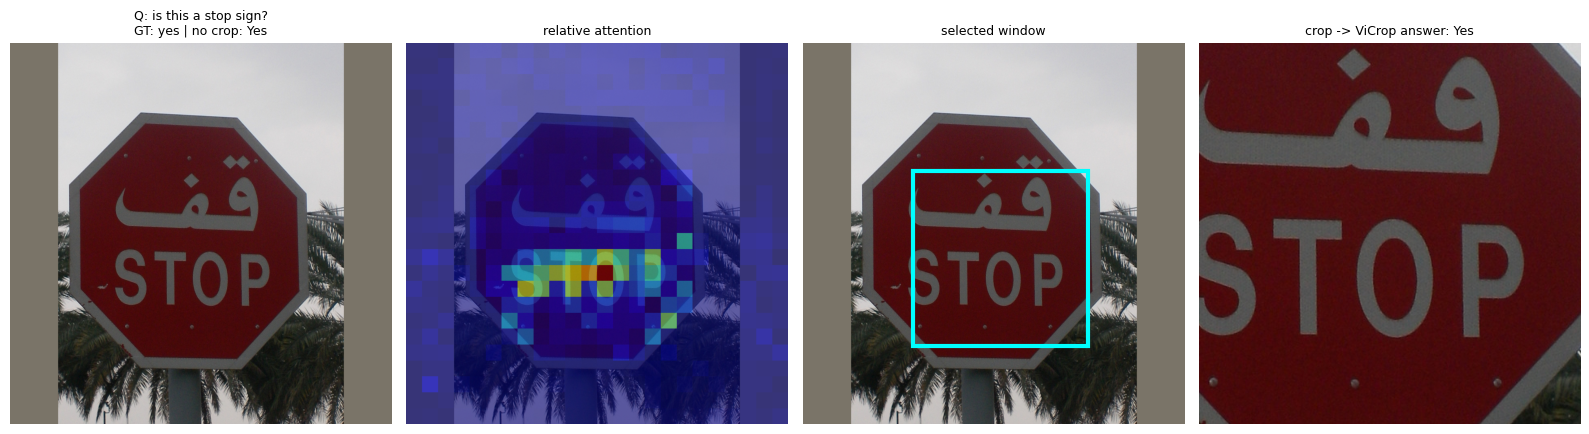

In [11]:
print(f"ViCrop broke the answer: {len(broke_r)} samples (failure cases)")
for r in broke_r[:2]: show(r)
print("Unchanged examples")
for r in same_r[:2]: show(r)

## 8. Takeaways

- The attention map concentrates on the region that holds the answer, even when the no-crop answer is wrong. This is the paper's claim: the model knows where to look, but cannot resolve small details at 336x336.
- Cropping that region and feeding it in as extra image tokens fixes many of these answers without any training.
- Failure cases: the window can include distractors or cut off the text, and only one region is selected (the paper's stated limitation).
- Cost: one extra forward pass for the generic prompt plus extra image tokens.